In [1]:
import pandas as pd
df = pd.read_csv("NGCC_Uncertainty_dataset.csv")

In [2]:
df

,Ambient Air Temperature (Dry Bulb Average) (°F),Natural Gas Cost ($/mscf),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg),Important Performance and Cost Factors: CO2 Removed (tons/hr),Important Performance and Cost Factors: Net Electrical Output (MW),Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton),Drift Loss (tons/hr),Evaporation (tons/hr)
0,75.137497,6.725,33.900002,60.674999,4.4425,135.200363,491.935730,328.892700,0.233573,0.000000
1,69.612503,5.875,43.700001,81.525002,5.9275,182.987564,477.473724,228.331604,0.187872,0.000000
2,84.912498,11.325,33.299999,61.875000,1.6525,136.096603,499.090912,449.124939,0.237666,0.000000
3,54.737499,2.425,15.300000,82.724998,5.5225,189.321732,489.426849,159.739182,0.540384,592.232117
4,18.187500,8.875,36.099998,63.375000,1.7425,151.950363,547.840698,362.821564,0.224505,468.949066
...,...,...,...,...,...,...,...,...,...,...
195,75.987503,9.025,11.700000,68.025002,2.8225,151.407898,496.516418,361.050995,0.686384,661.860474
196,59.837502,9.875,32.700001,81.224998,6.3325,184.661026,482.363220,311.367065,0.251914,149.858490
197,97.237503,9.725,19.100000,64.724998,5.4325,140.030426,469.309143,394.297119,0.415051,0.000000
198,57.287498,3.975,12.700000,62.174999,9.3475,141.821533,477.319916,253.032211,0.628880,579.553528


In [3]:
df.isna().sum()

Ambient Air Temperature (Dry Bulb Average) (°F)                       0
Natural Gas Cost ($/mscf)                                             0
Cooling Water Temperature Rise (°F)                                   0
Absorber CO2 Removal Efficiency (%)                                   0
Amine Scrubber Power Requirement (% MWg)                              0
Important Performance and Cost Factors: CO2 Removed (tons/hr)         0
Important Performance and Cost Factors: Net Electrical Output (MW)    0
Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton)         0
Drift Loss (tons/hr)                                                  0
Evaporation (tons/hr)                                                 0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
# water consumption = cooling-tower evaporation + drift
df['Water Consumption (tons/hr)'] = df['Evaporation (tons/hr)'] + df['Drift Loss (tons/hr)']

# high-ambient rows zero out evaporation (infeasible tower, not real). dropping
df = df[df['Evaporation (tons/hr)'] > 0].reset_index(drop=True)

In [6]:
df

,Ambient Air Temperature (Dry Bulb Average) (°F),Natural Gas Cost ($/mscf),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg),Important Performance and Cost Factors: CO2 Removed (tons/hr),Important Performance and Cost Factors: Net Electrical Output (MW),Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton),Drift Loss (tons/hr),Evaporation (tons/hr),Water Consumption (tons/hr)
0,54.737499,2.425,15.300000,82.724998,5.5225,189.321732,489.426849,159.739182,0.540384,592.232117,592.772501
1,18.187500,8.875,36.099998,63.375000,1.7425,151.950363,547.840698,362.821564,0.224505,468.949066,469.173571
2,23.287500,3.875,10.100000,62.775002,3.2725,149.551697,535.476746,243.739700,0.800109,500.177155,500.977263
3,50.062500,10.825,25.900000,89.175003,6.6025,205.320679,482.945038,302.977753,0.321777,579.196838,579.518615
4,73.437500,6.225,10.900000,81.675003,5.6125,182.403030,476.355743,245.441025,0.752240,657.447937,658.200177
...,...,...,...,...,...,...,...,...,...,...,...
112,40.287498,11.425,11.900000,64.425003,7.4125,150.209229,498.888763,435.278320,0.677926,541.692444,542.370370
113,75.987503,9.025,11.700000,68.025002,2.8225,151.407898,496.516418,361.050995,0.686384,661.860474,662.546858
114,59.837502,9.875,32.700001,81.224998,6.3325,184.661026,482.363220,311.367065,0.251914,149.858490,150.110404
115,57.287498,3.975,12.700000,62.174999,9.3475,141.821533,477.319916,253.032211,0.628880,579.553528,580.182408


In [7]:
x = df[['Ambient Air Temperature (Dry Bulb Average) (°F)',
    'Natural Gas Cost ($/mscf)',
    'Cooling Water Temperature Rise (°F)',
    'Absorber CO2 Removal Efficiency (%)',
    'Amine Scrubber Power Requirement (% MWg)']]

y = df['Water Consumption (tons/hr)']

In [8]:
x

,Ambient Air Temperature (Dry Bulb Average) (°F),Natural Gas Cost ($/mscf),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg)
0,54.737499,2.425,15.300000,82.724998,5.5225
1,18.187500,8.875,36.099998,63.375000,1.7425
2,23.287500,3.875,10.100000,62.775002,3.2725
3,50.062500,10.825,25.900000,89.175003,6.6025
4,73.437500,6.225,10.900000,81.675003,5.6125
...,...,...,...,...,...
112,40.287498,11.425,11.900000,64.425003,7.4125
113,75.987503,9.025,11.700000,68.025002,2.8225
114,59.837502,9.875,32.700001,81.224998,6.3325
115,57.287498,3.975,12.700000,62.174999,9.3475


In [9]:
y

0      592.772501
1      469.173571
2      500.977263
3      579.518615
4      658.200177
          ...    
112    542.370370
113    662.546858
114    150.110404
115    580.182408
116    498.290776
Name: Water Consumption (tons/hr), Length: 117, dtype: float64

In [10]:
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("\n=== SHAP MODELS ===\n")


=== SHAP MODELS ===



In [11]:
# Gradient Boosting Regressor
gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {
        "n_estimators": [100, 300],
        "max_depth": [3, 6, 10],
        "learning_rate": [0.01, 0.1, 0.3],
        "subsample": [0.8, 1.0],
        "max_features": [0.8, 1.0]
    },
    cv=5, scoring="r2", n_jobs=-1
)
gbr_grid.fit(x_train, y_train)

best_gbr = gbr_grid.best_estimator_
print("Gradient Boosting best params:", gbr_grid.best_params_)
print('Train R2:', best_gbr.score(x_train, y_train))
print('Test R2:', best_gbr.score(x_test, y_test))

Gradient Boosting best params: {'learning_rate': 0.3, 'max_depth': 10, 'max_features': 0.8, 'n_estimators': 300, 'subsample': 0.8}
Train R2: 1.0
Test R2: 0.9533401302673212


In [12]:
#Checking the RMSE and MAPE scores
from sklearn.metrics import mean_squared_error
import numpy as np

print("\n=== RMSE & MAPE ===\n")

models = {
    'Gradient Boost':    best_gbr
}

for name, model in models.items():
    y_pred = model.predict(x_test)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))
    mape   = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    print(f"{name} | RMSE: {rmse:.4f} | MAPE: {mape:.4f}%")


=== RMSE & MAPE ===

Gradient Boost | RMSE: 28.4104 | MAPE: 3.7739%


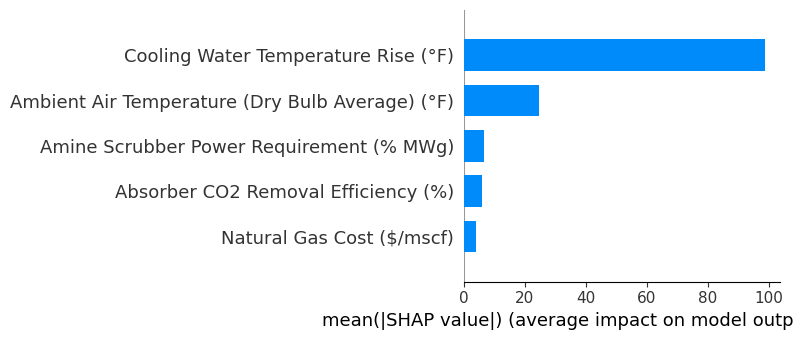

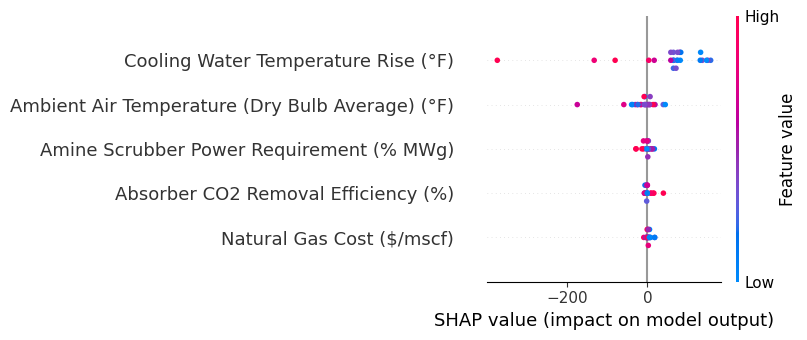

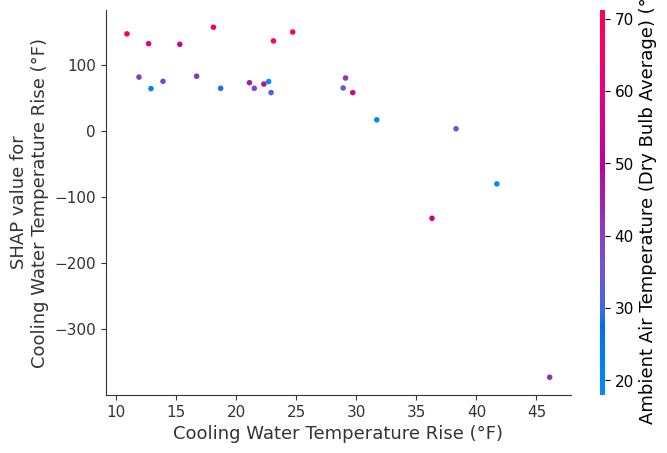

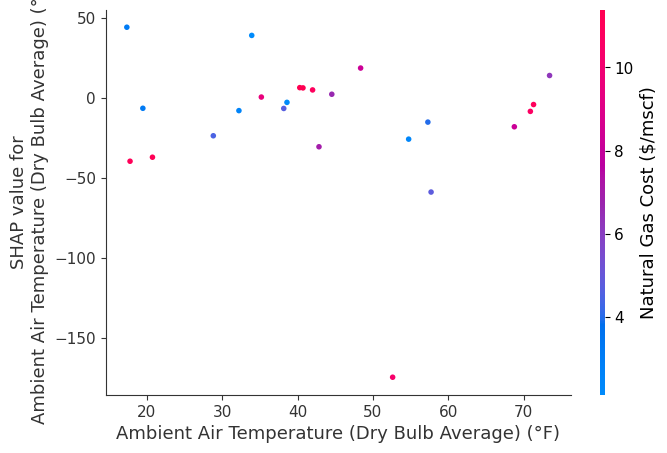

In [13]:
import shap, numpy as np
explainer   = shap.TreeExplainer(best_gbr)
shap_values = explainer.shap_values(x_test)

shap.summary_plot(shap_values, x_test, plot_type="bar")
shap.summary_plot(shap_values, x_test)

mean_abs = np.abs(shap_values).mean(axis=0)
order    = np.argsort(mean_abs)[::-1]
for i in order[:2]:
    shap.dependence_plot(x_test.columns[i], shap_values, x_test)